# Fused early-fusion MLP + ablation (price / technical / fundamentals / news)


## 0. Imports & config

In [33]:
import os, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras import Sequential, layers, callbacks
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error as MSE, r2_score

tf.get_logger().setLevel("ERROR")

PRICE_PATH = "/kaggle/input/datasets/raheenz/ubl-news-price/UBL.csv"
FUND_PATH  = "/kaggle/input/datasets/raheenz/ubl-news-price/UBL_fundamental_features.csv"
NEWS_PATH  = "/kaggle/input/datasets/raheenz/ubl-news-price/ubl_news_clean.csv"
FEAT_DIR   = "/kaggle/working"

START, END    = "2021-09-30", "2026-06-30"
W             = 30   
TRAIN_END, VAL_END = "2025-01-23", "2025-10-10" #  chronological split (on the date being predicted)
HALF_LIFE, N_PCA, RERUN_FINBERT = 3, 8, False
SEEDS = [42, 43, 44]
os.makedirs(FEAT_DIR, exist_ok=True)

## 1. Price: load & clean 

In [34]:
df = pd.read_csv(PRICE_PATH)
df.columns = df.columns.str.strip().str.upper()
df["DATE"] = pd.to_datetime(df["DATE"])
df = df[df["DATE"] >= "2021-01-01"].drop_duplicates()
ok = ((df[["OPEN","HIGH","LOW","CLOSE"]] > 0).all(axis=1) & (df["VOLUME"] >= 0)
      & (df["HIGH"] >= df[["OPEN","CLOSE","LOW"]].max(axis=1))
      & (df["LOW"] <= df[["OPEN","CLOSE","HIGH"]].min(axis=1)))
df = df[ok].sort_values("DATE")
df = df[(df.DATE >= START) & (df.DATE <= END)].reset_index(drop=True)
df["DATE"] = df["DATE"].astype("datetime64[ns]")
assert df.DATE.is_unique
print(len(df), df.DATE.min(), df.DATE.max())

1176 2021-09-30 00:00:00 2026-06-30 00:00:00


## 2. Price features & target

In [35]:
df["ret"] = np.log(df.CLOSE).diff()
df["hl_range"] = (df.HIGH - df.LOW) / df.CLOSE
df["oc_change"] = (df.CLOSE - df.OPEN) / df.OPEN
df["log_vol"] = np.log1p(df.VOLUME)
df["ma5_ratio"] = df.CLOSE / df.CLOSE.rolling(5).mean() - 1
df["ma20_ratio"] = df.CLOSE / df.CLOSE.rolling(20).mean() - 1
df["vol10"] = df.ret.rolling(10).std()
df["target_ret"] = df.ret.shift(-1)          # next-day log return
df["tdate"] = df.DATE.shift(-1)              # date being predicted
df["next_close"] = df.CLOSE.shift(-1)

PRICE_F = ["ret","hl_range","oc_change","log_vol","ma5_ratio","ma20_ratio","vol10"]

## 3. Technical indicators 

In [36]:
!pip install -q TA-Lib

In [37]:
import talib

close, high, low = df["CLOSE"].values.astype(float), df["HIGH"].values.astype(float), df["LOW"].values.astype(float)

df["EMA_12"] = talib.EMA(close, timeperiod=12)
df["EMA_26"] = talib.EMA(close, timeperiod=26)
df["MACD"], _, _ = talib.MACD(close, fastperiod=12, slowperiod=26, signalperiod=9)
df["SAR"] = talib.SAR(high, low, acceleration=0.02, maximum=0.2)
df["BB_UPPER"], df["BB_MIDDLE"], df["BB_LOWER"] = talib.BBANDS(
    close, timeperiod=20, nbdevup=2, nbdevdn=2, matype=0)
df["SLOWK"], df["SLOWD"] = talib.STOCH(
    high, low, close, fastk_period=5, slowk_period=3, slowk_matype=0,
    slowd_period=3, slowd_matype=0)

TECH = ["OPEN","HIGH","LOW","CLOSE","VOLUME",
        "EMA_12","EMA_26","MACD","SAR",
        "BB_UPPER","BB_MIDDLE","BB_LOWER","SLOWK","SLOWD"]

## 4. Fundamentals: load, impute, merge backward on filing date


In [38]:
fund = pd.read_csv(FUND_PATH, na_values=["-", "--", ""])
fund = fund.rename(columns={"Unnamed: 0": "QUARTER", "Unnamed: 1": "DATE"})
fund["DATE"] = pd.to_datetime(fund["DATE"].str.extract(r"([A-Z][a-z]{2} \d{2}, \d{4})")[0])
fund = fund.sort_values("DATE").reset_index(drop=True)

# STEP 1: derivable YoY growth fields
fund["Revenue Growth (YoY)"] = fund["Revenue Growth (YoY)"].fillna(fund["Revenue"].pct_change(4) * 100)
fund["Net Income Growth"]    = fund["Net Income Growth"].fillna(fund["Net Income"].pct_change(4) * 100)
fund["EPS Growth"]           = fund["EPS Growth"].fillna(fund["EPS (Basic)"].pct_change(4) * 100)

# STEP 2: fill missing raw values with mean of previous 4 quarters
for col in ["Revenue", "Net Income", "EPS (Basic)", "EPS (Diluted)"]:
    rolling_mean = fund[col].shift(1).rolling(window=4, min_periods=2).mean()
    fund[col] = fund[col].fillna(rolling_mean)

# STEP 3: recalc derived growth fields
fund["Revenue Growth (YoY)"] = fund["Revenue Growth (YoY)"].fillna(fund["Revenue"].pct_change(4) * 100)
fund["Net Income Growth"]    = fund["Net Income Growth"].fillna(fund["Net Income"].pct_change(4) * 100)
fund["EPS Growth"]           = fund["EPS Growth"].fillna(fund["EPS (Basic)"].pct_change(4) * 100)

# ---- leak-safe merge: latest filing on/before each trading day ----
fund["DATE"] = fund["DATE"].astype("datetime64[ns]")
fund["FUND_ASOF"] = fund["DATE"]
merged = pd.merge_asof(df[["DATE"]], fund, on="DATE", direction="backward")

for col in ["Revenue Growth (YoY)", "Net Income Growth", "EPS Growth"]:
    merged[col] = pd.to_numeric(merged[col].astype(str).str.replace("%", "", regex=False), errors="coerce")

FUND = ["Revenue", "Revenue Growth (YoY)", "Net Income", "Net Income Growth",
        "EPS (Basic)", "EPS (Diluted)", "EPS Growth", "Total Assets", "Cash & Equivalents"]
for c in FUND: df[c] = merged[c].astype(float).values
df["fund_asof"] = merged["FUND_ASOF"].values
assert (df["fund_asof"].dropna() <= df.loc[df["fund_asof"].notna(), "DATE"]).all()   # no look-ahead
print("days before first filing (no fundamentals yet):", int(df["fund_asof"].isna().sum()))

days before first filing (no fundamentals yet): 0


/tmp/ipykernel_50/3899897271.py:7: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  fund["Revenue Growth (YoY)"] = fund["Revenue Growth (YoY)"].fillna(fund["Revenue"].pct_change(4) * 100)
/tmp/ipykernel_50/3899897271.py:8: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  fund["Net Income Growth"]    = fund["Net Income Growth"].fillna(fund["Net Income"].pct_change(4) * 100)
/tmp/ipykernel_50/3899897271.py:9: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or spec

## 5. News: FinBERT cache → daily features aligned on `feature_date` 

In [39]:
CACHE_S, CACHE_E = f"{FEAT_DIR}/article_scored.csv", f"{FEAT_DIR}/article_emb.npy"

if os.path.exists(CACHE_S) and os.path.exists(CACHE_E) and not RERUN_FINBERT:
    arts = pd.read_csv(CACHE_S, parse_dates=["pub_date", "feature_date"]); E = np.load(CACHE_E)
    print(f"loaded cached FinBERT output: {len(arts)} articles")
else:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("device:", device)

    arts = pd.read_csv(NEWS_PATH, parse_dates=["pub_date", "feature_date"])
    tok = AutoTokenizer.from_pretrained("ProsusAI/finbert")
    model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").to(device).eval()
    id2 = {int(k): v.lower() for k, v in model.config.id2label.items()}
    POS, NEG, NEU = [[k for k, v in id2.items() if v == name][0] for name in ("positive", "negative", "neutral")]

    # split long articles into 510-token chunks
    chunks = []
    for i, (t, x) in enumerate(zip(arts["title"], arts["text"])):
        ids = tok(f"{t}. {x}", add_special_tokens=False)["input_ids"]
        for s in range(0, max(len(ids), 1), 510):
            chunks.append((i, ids[s:s + 510]))
    print(f"{len(arts)} articles -> {len(chunks)} chunks")

    BATCH, probs, embs = 8, [], []
    with torch.no_grad():
        for b in range(0, len(chunks), BATCH):
            batch = [[tok.cls_token_id] + ids + [tok.sep_token_id] for _, ids in chunks[b:b + BATCH]]
            L = max(len(x) for x in batch)
            input_ids = torch.tensor([x + [tok.pad_token_id] * (L - len(x)) for x in batch]).to(device)
            out = model(input_ids=input_ids, attention_mask=(input_ids != tok.pad_token_id).long(), output_hidden_states=True)
            probs.append(torch.softmax(out.logits, -1).cpu().numpy())
            embs.append(out.hidden_states[-1][:, 0, :].cpu().numpy())
            if (b // BATCH) % 10 == 0: print(f"  {min(b + BATCH, len(chunks))}/{len(chunks)} chunks")
    probs, embs = np.vstack(probs), np.vstack(embs)

    # chunks -> articles
    rows = np.array([r for r, _ in chunks]); w = np.array([len(ids) for _, ids in chunks], float)
    P, E, Wt = np.zeros((len(arts), 3)), np.zeros((len(arts), 768)), np.zeros(len(arts))
    np.add.at(P, rows, probs * w[:, None]); np.add.at(E, rows, embs * w[:, None]); np.add.at(Wt, rows, w)
    P /= Wt[:, None]; E /= Wt[:, None]
    arts["p_pos"], arts["p_neg"], arts["p_neu"] = P[:, POS], P[:, NEG], P[:, NEU]
    arts["sentiment"] = arts["p_pos"] - arts["p_neg"]
    arts.to_csv(CACHE_S, index=False); np.save(CACHE_E, E)
    print("saved FinBERT output to", FEAT_DIR)

loaded cached FinBERT output: 277 articles


In [40]:
# each article -> the first trading day on/after its feature_date
arts["feature_date"] = arts["feature_date"].astype("datetime64[ns]")
arts["row"] = np.arange(len(arts))
a = pd.merge_asof(arts.sort_values("feature_date"), df[["DATE"]].rename(columns={"DATE": "trade_date"}),
                  left_on="feature_date", right_on="trade_date", direction="forward").dropna(subset=["trade_date"]).reset_index(drop=True)
assert (a["trade_date"] >= a["feature_date"]).all()                                   # no look-ahead
E_s = E[a["row"].values]

g = a.groupby("trade_date")
daily = pd.DataFrame({"n_articles": g.size(), "sent_mean": g["sentiment"].mean(),
                      "sent_extreme": g["sentiment"].agg(lambda s: s.loc[s.abs().idxmax()])})
df = df.join(daily, on="DATE")
df["has_news"] = df["n_articles"].notna().astype(int)
df[["n_articles", "sent_mean", "sent_extreme"]] = df[["n_articles", "sent_mean", "sent_extreme"]].fillna(0)

D = np.zeros((len(df), 768)); pos = {d: i for i, d in enumerate(df["DATE"])}
for d, idx_ in g.indices.items(): D[pos[d]] = E_s[idx_].mean(axis=0)

# news recency / memory features (causal loop)
ds, last, m, memo, decay = [], -1, 0.0, [], 0.5 ** (1 / HALF_LIFE)
for i, (h, s) in enumerate(zip(df["has_news"], df["sent_mean"])):
    if h: last = i
    ds.append(i - last if last >= 0 else 60); m = m * decay + s; memo.append(m)
df["recency"] = 0.5 ** (np.minimum(ds, 60) / HALF_LIFE)
df["sent_decay"] = memo

NEWS = ["n_articles", "sent_mean", "sent_extreme", "has_news", "recency", "sent_decay"]
print(f"days with news: {int(df.has_news.sum())} ({df.has_news.mean():.1%})")

days with news: 167 (14.2%)


## 6. Unified sample table + chronological split
One row per sample `t`: price window `[t-29..t]`, tech/fund/news at `t`, target = return `t→t+1`. A sample exists only if **all four blocks** are available, so every ablation variant is trained and scored on the identical rows. Split is on the date being predicted (`tdate`); no shuffling.

In [41]:
price_ok = df[PRICE_F].notna().all(axis=1)
win_ok   = price_ok.astype(int).rolling(W).sum().eq(W)
tech_ok  = df[TECH].notna().all(axis=1)
fund_ok  = df[FUND].notna().all(axis=1)
tgt_ok   = df[["target_ret", "tdate", "next_close"]].notna().all(axis=1)
print(f"raw days {len(df)} | price-window ok {win_ok.sum()} | tech ok {tech_ok.sum()} | fund ok {fund_ok.sum()} | target ok {tgt_ok.sum()}")

idx = np.where((win_ok & tech_ok & fund_ok & tgt_ok).values)[0]
print("unified samples:", len(idx), "| interior gaps:", int((np.diff(idx) > 1).sum()))

Xp = np.stack([df[PRICE_F].values[i-W+1:i+1] for i in idx])        # (N, W, 7)
Xt = df[TECH].values[idx]
Xf = df[FUND].values[idx]
Xn_raw = df[NEWS].values[idx]
Dm  = D[idx]; has = df["has_news"].values[idx]
y   = df["target_ret"].values[idx]
td  = pd.DatetimeIndex(df["tdate"].values[idx])
pc  = df["CLOSE"].values[idx]                 # today's close
nc  = df["next_close"].values[idx]            # actual next close

tr = np.asarray(td <= pd.Timestamp(TRAIN_END))
va = np.asarray((td > pd.Timestamp(TRAIN_END)) & (td <= pd.Timestamp(VAL_END)))
te = np.asarray(td > pd.Timestamp(VAL_END))
print("train / val / test:", tr.sum(), va.sum(), te.sum())
assert td[tr].max() < td[va].min() and td[va].max() < td[te].min()   # chronological, no overlap

raw days 1176 | price-window ok 1128 | tech ok 1143 | fund ok 1176 | target ok 1175
unified samples: 1127 | interior gaps: 0
train / val / test: 774 176 177


In [42]:
# ===== 6.1 Export feature files + fused dataset + dictionary =====
BASE   = ["DATE", "OPEN", "HIGH", "LOW", "CLOSE", "VOLUME"]
TECH_X = [c for c in TECH if c not in BASE]          # indicators only (OHLCV lives in price)
TARGET = ["target_ret", "tdate", "next_close"]

# 1) technical indicators (DATE-keyed)
df[["DATE"] + TECH_X].to_csv(f"{FEAT_DIR}/technical_indicators.csv", index=False)

# 2) news features (DATE-keyed) + daily FinBERT embeddings (row i = df row i)
df[["DATE"] + NEWS].to_csv(f"{FEAT_DIR}/news_features.csv", index=False)
np.save(f"{FEAT_DIR}/news_daily_finbert768.npy", D)

# 3) fundamentals after imputation (quarterly, one row per filing)
fund.to_csv(f"{FEAT_DIR}/fundamentals_imputed.csv", index=False)

# 4) fused dataset: price + price features + technical + fundamentals + news + target
fused = df[BASE + PRICE_F + TECH_X + FUND + ["fund_asof"] + NEWS + TARGET].copy()
fused["in_unified"] = 0;          fused.loc[idx, "in_unified"] = 1
fused["split"] = "excluded"
fused.loc[idx[tr], "split"] = "train"
fused.loc[idx[va], "split"] = "val"
fused.loc[idx[te], "split"] = "test"
fused.to_csv(f"{FEAT_DIR}/ubl_fused_dataset.csv", index=False)

# 5) data dictionary
desc = {
 "DATE": ("price", "Trading day t (feature date)"),
 "OPEN": ("price", "Opening price"), "HIGH": ("price", "Daily high"), "LOW": ("price", "Daily low"),
 "CLOSE": ("price", "Closing price"), "VOLUME": ("price", "Shares traded"),
 "ret": ("price", "Log return ln(CLOSE_t / CLOSE_t-1)"),
 "hl_range": ("price", "(HIGH - LOW) / CLOSE"),
 "oc_change": ("price", "(CLOSE - OPEN) / OPEN"),
 "log_vol": ("price", "log(1 + VOLUME)"),
 "ma5_ratio": ("price", "CLOSE / 5-day MA - 1"),
 "ma20_ratio": ("price", "CLOSE / 20-day MA - 1"),
 "vol10": ("price", "10-day rolling std of ret"),
 "EMA_12": ("technical", "12-day EMA"), "EMA_26": ("technical", "26-day EMA"),
 "MACD": ("technical", "MACD line (12/26/9)"), "SAR": ("technical", "Parabolic SAR (0.02/0.2)"),
 "BB_UPPER": ("technical", "Bollinger upper (20, 2 std)"), "BB_MIDDLE": ("technical", "Bollinger middle (20-day SMA)"),
 "BB_LOWER": ("technical", "Bollinger lower (20, 2 std)"),
 "SLOWK": ("technical", "Stochastic %K (5,3,3)"), "SLOWD": ("technical", "Stochastic %D (5,3,3)"),
 "Revenue": ("fundamental", "Quarterly revenue (gaps imputed: mean of prev 4 quarters)"),
 "Revenue Growth (YoY)": ("fundamental", "YoY revenue growth %"),
 "Net Income": ("fundamental", "Quarterly net income (imputed as above)"),
 "Net Income Growth": ("fundamental", "YoY net income growth %"),
 "EPS (Basic)": ("fundamental", "Basic EPS (imputed as above)"),
 "EPS (Diluted)": ("fundamental", "Diluted EPS (imputed as above)"),
 "EPS Growth": ("fundamental", "YoY EPS growth %"),
 "Total Assets": ("fundamental", "Total assets"), "Cash & Equivalents": ("fundamental", "Cash & equivalents"),
 "fund_asof": ("fundamental", "Filing date of latest report known on day t (backward merge, no look-ahead)"),
 "n_articles": ("news", "Articles mapped to this trading day"),
 "sent_mean": ("news", "Mean FinBERT sentiment (p_pos - p_neg) that day"),
 "sent_extreme": ("news", "Sentiment of the article with the largest |sentiment|"),
 "has_news": ("news", "1 if at least one article that day"),
 "recency": ("news", f"0.5^(days since last news / {HALF_LIFE}), capped at 60 days"),
 "sent_decay": ("news", f"Exponentially decayed running sentiment (half-life {HALF_LIFE} days)"),
 "target_ret": ("target", "Next-day log return (t -> t+1)"),
 "tdate": ("target", "Date being predicted (t+1); splits are done on this"),
 "next_close": ("target", "Actual next-day close"),
 "in_unified": ("meta", "1 if row has all 4 blocks + full 30-day window + target"),
 "split": ("meta", f"train (<= {TRAIN_END}) / val (<= {VAL_END}) / test / excluded"),
}
dd = pd.DataFrame([(c, *desc[c]) for c in fused.columns], columns=["column", "block", "description"])
dd["non_null"] = [int(fused[c].notna().sum()) for c in dd["column"]]
dd.to_csv(f"{FEAT_DIR}/ubl_fused_dataset_DICTIONARY.csv", index=False)

print("fused:", fused.shape, "| unified rows:", int(fused.in_unified.sum()), "|", fused.split.value_counts().to_dict())
dd

fused: (1176, 43) | unified rows: 1127 | {'train': 774, 'test': 177, 'val': 176, 'excluded': 49}


,column,block,description,non_null
0,DATE,price,Trading day t (feature date),1176
1,OPEN,price,Opening price,1176
2,HIGH,price,Daily high,1176
3,LOW,price,Daily low,1176
4,CLOSE,price,Closing price,1176
5,VOLUME,price,Shares traded,1176
6,ret,price,Log return ln(CLOSE_t / CLOSE_t-1),1175
7,hl_range,price,(HIGH - LOW) / CLOSE,1176
8,oc_change,price,(CLOSE - OPEN) / OPEN,1176
9,log_vol,price,log(1 + VOLUME),1176


## 7. Per-block scalers (fit on train only) → feature blocks

In [10]:
blocks = {}

# price: StandardScaler on windowed features, flattened  
sx = StandardScaler().fit(Xp[tr].reshape(-1, len(PRICE_F)))
blocks["price"] = sx.transform(Xp.reshape(-1, len(PRICE_F))).reshape(len(Xp), -1)

# technical: StandardScaler
blocks["tech"] = StandardScaler().fit(Xt[tr]).transform(Xt)

# fundamentals: StandardScaler 
blocks["fund"] = StandardScaler().fit(Xf[tr]).transform(Xf)

# news: PCA on FinBERT embeddings (fit on train news-days only, zero on no-news days) + StandardScaler  
pca = PCA(N_PCA, random_state=0).fit(Dm[tr][has[tr] == 1])
EMB = pca.transform(Dm) * has[:, None]
Xn = np.hstack([Xn_raw, EMB])
blocks["news"] = StandardScaler().fit(Xn[tr]).transform(Xn)

print({k: v.shape for k, v in blocks.items()})

{'price': (1127, 210), 'tech': (1127, 14), 'fund': (1127, 9), 'news': (1127, 14)}


## 8. Models & metrics  

In [11]:
def metrics(actual, pred, prev):
    return {
        "MAE": MAE(actual, pred),
        "RMSE": np.sqrt(MSE(actual, pred)),
        "MAPE": np.mean(np.abs((actual - pred) / actual)) * 100,
        "R²": r2_score(actual, pred),
        "Dir. acc.": np.mean(np.sign(actual - prev) == np.sign(pred - prev)) * 100,
    }

def build_price_mlp(n_in):
    m = Sequential([layers.Input((n_in,)), layers.Dense(64, activation="relu"), layers.Dropout(0.2),
                    layers.Dense(32, activation="relu"), layers.Dense(1)])
    m.compile("adam", "mse"); return m

def build_mlp(n_in):
    m = Sequential([layers.Input((n_in,)), layers.Dense(64, activation="relu"),
                    layers.Dense(32, activation="relu"), layers.Dense(1)])
    m.compile("adam", "mse", metrics=["mae"]); return m

PRICE_CFG = dict(build=build_price_mlp, epochs=100, patience=15, ysc=StandardScaler)
STD_CFG   = dict(build=build_mlp,       epochs=200, patience=20, ysc=StandardScaler)
CFG = {
    "Price":              dict(blocks=["price"], **PRICE_CFG),
    "Technical":          dict(blocks=["tech"],  **STD_CFG),   
    "Fundamentals":       dict(blocks=["fund"],  **STD_CFG),
    "News":               dict(blocks=["news"],  **STD_CFG),
    "Price+Tech":         dict(blocks=["price", "tech"], **STD_CFG),
    "Price+Tech+Fund":    dict(blocks=["price", "tech", "fund"], **STD_CFG),
    "All-4 fused":        dict(blocks=["price", "tech", "fund", "news"], **STD_CFG),
}

def run_one(name, seed):
    c = CFG[name]
    X = np.hstack([blocks[b] for b in c["blocks"]])                # early fusion = concat scaled blocks
    ysc = c["ysc"]().fit(y[tr].reshape(-1, 1))                     # y scaler fit on train only
    ytr, yva = ysc.transform(y[tr].reshape(-1, 1)), ysc.transform(y[va].reshape(-1, 1))
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    mdl = c["build"](X.shape[1])
    mdl.fit(X[tr], ytr, validation_data=(X[va], yva), epochs=c["epochs"], batch_size=32, verbose=0,
            callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=c["patience"], restore_best_weights=True)])
    out = {}
    for sname, msk in (("Validation", va), ("Test", te)):
        r = ysc.inverse_transform(mdl.predict(X[msk], verbose=0)).ravel()       # predicted return
        out[sname] = metrics(nc[msk], pc[msk] * np.exp(r), pc[msk])             # -> implied next close
    return out

## 9. Run ablation (3 seeds)

In [16]:
rows = []
for name in CFG:
    for seed in SEEDS:
        res = run_one(name, seed)
        for sname, m_ in res.items():
            rows.append({"Model": name, "Seed": seed, "Split": sname, **m_})
        print(f"{name:<18} seed {seed}: test DirAcc {res['Test']['Dir. acc.']:.1f}%  MAPE {res['Test']['MAPE']:.2f}%")

raw = pd.DataFrame(rows)
raw.to_csv(f"{FEAT_DIR}/ablation_raw_per_seed.csv", index=False)

Price              seed 42: test DirAcc 45.2%  MAPE 2.13%
Price              seed 43: test DirAcc 53.7%  MAPE 2.13%
Price              seed 44: test DirAcc 58.2%  MAPE 2.00%
Technical          seed 42: test DirAcc 48.6%  MAPE 2.07%
Technical          seed 43: test DirAcc 48.6%  MAPE 2.28%
Technical          seed 44: test DirAcc 49.7%  MAPE 2.14%
Fundamentals       seed 42: test DirAcc 45.8%  MAPE 2.34%
Fundamentals       seed 43: test DirAcc 45.8%  MAPE 1.97%
Fundamentals       seed 44: test DirAcc 45.8%  MAPE 2.14%
News               seed 42: test DirAcc 48.6%  MAPE 1.96%
News               seed 43: test DirAcc 51.4%  MAPE 2.07%
News               seed 44: test DirAcc 49.7%  MAPE 2.15%
Price+Tech         seed 42: test DirAcc 50.8%  MAPE 2.16%
Price+Tech         seed 43: test DirAcc 50.3%  MAPE 2.19%
Price+Tech         seed 44: test DirAcc 49.7%  MAPE 2.18%
Price+Tech+Fund    seed 42: test DirAcc 53.1%  MAPE 2.38%
Price+Tech+Fund    seed 43: test DirAcc 46.9%  MAPE 2.72%
Price+Tech+Fun

## 10. Ablation table (test set, mean ± std over 3 seeds; sorted by DirAcc)

In [13]:
METRICS = ["Dir. acc.", "MAE", "RMSE", "MAPE", "R²"]
test = raw[raw.Split == "Test"]
agg = test.groupby("Model")[METRICS].agg(["mean", "std"])          # std = sample std (ddof=1)

DEC = {"Dir. acc.": 1, "MAE": 2, "RMSE": 2, "MAPE": 2, "R²": 3}
def pm(m, n):
    u = "%" if m in ("Dir. acc.", "MAPE") else ""
    return f"{agg[m]['mean'][n]:.{DEC[m]}f}{u} ± {agg[m]['std'][n]:.{DEC[m]}f}{u}"

tbl = pd.DataFrame({m: [pm(m, n) for n in agg.index] for m in METRICS}, index=agg.index)
tbl.insert(0, "Blocks", [" + ".join(CFG[n]["blocks"]) for n in tbl.index])
tbl = tbl.loc[agg["Dir. acc."]["mean"].sort_values(ascending=False).index]

# reference rows
naive = metrics(nc[te], pc[te], pc[te])
print(f"Naive (close[t]) test: MAE {naive['MAE']:.2f} RMSE {naive['RMSE']:.2f} MAPE {naive['MAPE']:.2f}% R² {naive['R²']:.3f} DirAcc n/a")
print(f"Always-UP baseline DirAcc: {np.mean(nc[te] > pc[te]) * 100:.1f}%  (test n = {te.sum()})")

tbl.to_csv(f"{FEAT_DIR}/ablation_table_test.csv")
tbl

Naive (close[t]) test: MAE 7.86 RMSE 11.10 MAPE 1.94% R² 0.942 DirAcc n/a
Always-UP baseline DirAcc: 45.8%  (test n = 177)


,Blocks,Dir. acc.,MAE,RMSE,MAPE,R²
Model,,,,,,
Price,price,52.4% ± 6.6%,8.42 ± 0.31,11.83 ± 0.30,2.08% ± 0.08%,0.934 ± 0.003
Price+Tech,price + tech,50.3% ± 0.6%,8.84 ± 0.11,11.94 ± 0.35,2.17% ± 0.02%,0.933 ± 0.004
News,news,49.9% ± 1.4%,8.38 ± 0.41,11.56 ± 0.45,2.06% ± 0.09%,0.937 ± 0.005
Price+Tech+Fund,price + tech + fund,49.5% ± 3.2%,10.40 ± 0.66,13.26 ± 0.67,2.57% ± 0.17%,0.917 ± 0.008
Technical,tech,49.0% ± 0.7%,8.68 ± 0.41,11.90 ± 0.41,2.16% ± 0.11%,0.933 ± 0.005
All-4 fused,price + tech + fund + news,47.8% ± 1.8%,9.97 ± 0.99,12.99 ± 0.80,2.47% ± 0.25%,0.921 ± 0.010
Fundamentals,fund,45.8% ± 0.0%,8.69 ± 0.75,11.59 ± 0.52,2.15% ± 0.19%,0.937 ± 0.006


## 11: Rolling Window Config

In [28]:
# ===== 11. Rolling-window walk-forward (fixed-size window) =====
WF_STEP      = 21                  # retrain every 21 trading days (~1 month)
WF_INNER_VAL = 0.15                # last 15% of each window = early-stopping validation
WF_MODELS    = list(CFG)           # e.g. ["All-4 fused"] for a quick run
# WF_SEEDS     = SEEDS
SEED = 44

N           = len(idx)
WF_START    = int(np.flatnonzero(te)[0])      # first test sample = first fold start
ROLL_WINDOW = WF_START                        # rows before the test period (train + val), kept fixed
fd          = pd.DatetimeIndex(df["DATE"].values[idx])   # feature date (day t) of each sample
FOLD_STARTS = list(range(WF_START, N, WF_STEP))
print(f"samples {N} | ROLL_WINDOW {ROLL_WINDOW} | folds {len(FOLD_STARTS)} | "
      f"first test target date {td[WF_START].date()}")

samples 1127 | ROLL_WINDOW 950 | folds 9 | first test target date 2025-10-13


## 11.1: per-fold preprocessing and fit/predict

In [18]:
def make_fold(start):
    """Fixed-size window ending right before `start`; all scalers/PCA refit on this fold's fit rows only."""
    end      = min(start + WF_STEP, N)
    test_pos = np.arange(start, end)
    pool     = np.arange(start - ROLL_WINDOW, start)                 # rolling: drops oldest rows each fold
    elig     = pool[td[pool] <= fd[test_pos[0]]]                     # purge: targets must be known before first test day
    n_val    = max(1, int(np.ceil(len(elig) * WF_INNER_VAL)))
    cut      = len(elig) - n_val - 1                                 # 1-row gap between fit and inner-val
    fit_pos, val_pos = elig[:cut], elig[cut + 1:]
    assert len(fit_pos) > 50 and len(val_pos) > 5
    assert td[elig].max() < td[test_pos].min(), "temporal leakage"

    B = {}
    def put(name, tf_fn):                                            # tf_fn(pos) -> scaled block
        B[name] = tuple(tf_fn(p) for p in (fit_pos, val_pos, test_pos))

    # price
    sp = StandardScaler().fit(Xp[fit_pos].reshape(-1, len(PRICE_F)))
    put("price", lambda p: sp.transform(Xp[p].reshape(-1, len(PRICE_F))).reshape(len(p), -1))
    # technical
    st = StandardScaler().fit(Xt[fit_pos]);  put("tech", lambda p: st.transform(Xt[p]))
    # fundamentals
    sf = StandardScaler().fit(Xf[fit_pos]);  put("fund", lambda p: sf.transform(Xf[p]))
    # news: PCA on fit news-days only, zero on no-news days, then scaler
    nd = fit_pos[has[fit_pos] == 1]
    assert len(nd) >= N_PCA, f"only {len(nd)} news-days in window for PCA({N_PCA})"
    pca_f = PCA(N_PCA, random_state=0).fit(Dm[nd])
    news_raw = lambda p: np.hstack([Xn_raw[p], pca_f.transform(Dm[p]) * has[p][:, None]])
    sn = StandardScaler().fit(news_raw(fit_pos));  put("news", lambda p: sn.transform(news_raw(p)))

    ysc = StandardScaler().fit(y[fit_pos].reshape(-1, 1))
    return dict(B=B, ysc=ysc, fit=fit_pos, val=val_pos, test=test_pos, elig=elig)

def fit_predict(name, seed, F):
    c = CFG[name]
    cat = lambda k: np.hstack([F["B"][b][k] for b in c["blocks"]])
    Xf_, Xv_, Xt_ = cat(0), cat(1), cat(2)
    yf = F["ysc"].transform(y[F["fit"]].reshape(-1, 1))
    yv = F["ysc"].transform(y[F["val"]].reshape(-1, 1))
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    mdl = c["build"](Xf_.shape[1])
    mdl.fit(Xf_, yf, validation_data=(Xv_, yv), epochs=c["epochs"], batch_size=32, verbose=0,
            callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=c["patience"], restore_best_weights=True)])
    r = F["ysc"].inverse_transform(mdl.predict(Xt_, verbose=0)).ravel()      # predicted log return
    return pc[F["test"]] * np.exp(r)                                         # implied next close

## 11.2: run the walk-forward

In [24]:
wf_rows = []
for k, start in enumerate(FOLD_STARTS, 1):
    F = make_fold(start); tp = F["test"]
    print(f"fold {k:>2}/{len(FOLD_STARTS)} | window {len(F['elig'])} rows "
          f"({td[F['elig'][0]].date()} -> {td[F['elig'][-1]].date()}) | "
          f"test {len(tp)} ({td[tp[0]].date()} -> {td[tp[-1]].date()})")
    for name in WF_MODELS:
        pred = fit_predict(name, 44, F)
        wf_rows.append(pd.DataFrame({"fold": k, "Model": name, "DATE": td[tp],
                                     "prev_close": pc[tp], "actual": nc[tp], "pred": pred}))
wf = pd.concat(wf_rows, ignore_index=True)
wf.to_csv(f"{FEAT_DIR}/wf_rolling_predictions.csv", index=False)
print("done:", len(wf), "prediction rows")

fold  1/9 | window 950 rows (2021-12-09 -> 2025-10-10) | test 21 (2025-10-13 -> 2025-11-10)
fold  2/9 | window 950 rows (2022-01-07 -> 2025-11-10) | test 21 (2025-11-11 -> 2025-12-09)
fold  3/9 | window 950 rows (2022-02-07 -> 2025-12-09) | test 21 (2025-12-10 -> 2026-01-08)
fold  4/9 | window 950 rows (2022-03-08 -> 2026-01-08) | test 21 (2026-01-09 -> 2026-02-09)
fold  5/9 | window 950 rows (2022-04-07 -> 2026-02-09) | test 21 (2026-02-10 -> 2026-03-10)
fold  6/9 | window 950 rows (2022-05-13 -> 2026-03-10) | test 21 (2026-03-11 -> 2026-04-10)
fold  7/9 | window 950 rows (2022-06-13 -> 2026-04-10) | test 21 (2026-04-13 -> 2026-05-12)
fold  8/9 | window 950 rows (2022-07-15 -> 2026-05-12) | test 21 (2026-05-13 -> 2026-06-15)
fold  9/9 | window 950 rows (2022-08-17 -> 2026-06-15) | test 9 (2026-06-16 -> 2026-06-30)
done: 1239 prediction rows


## 11.3: summary table 

In [29]:
DEC = {"Dir. acc.": 1, "MAE": 2, "RMSE": 2, "MAPE": 2, "R²": 3}

raw_wf = pd.DataFrame([{"Model": m, **metrics(g.actual.values, g.pred.values, g.prev_close.values)}
                       for m, g in wf.groupby("Model")]).set_index("Model")
raw_wf.to_csv(f"{FEAT_DIR}/wf_rolling_raw.csv")

def fmt(m, v):
    u = "%" if m in ("Dir. acc.", "MAPE") else ""
    return f"{v:.{DEC[m]}f}{u}"

tbl_wf = pd.DataFrame({m: [fmt(m, v) for v in raw_wf[m]] for m in METRICS}, index=raw_wf.index)
tbl_wf.insert(0, "Blocks", [" + ".join(CFG[n]["blocks"]) for n in tbl_wf.index])
tbl_wf = tbl_wf.loc[raw_wf["Dir. acc."].sort_values(ascending=False).index]

one = wf[wf.Model == WF_MODELS[0]]                       # same test rows for every model
naive_wf = metrics(one.actual.values, one.prev_close.values, one.prev_close.values)
print(f"Rolling WF rows: {len(one)} | seed {SEED} | Naive: MAE {naive_wf['MAE']:.2f} "
      f"RMSE {naive_wf['RMSE']:.2f} MAPE {naive_wf['MAPE']:.2f}% R² {naive_wf['R²']:.3f} | "
      f"Always-UP DirAcc {np.mean(one.actual.values > one.prev_close.values) * 100:.1f}%")
tbl_wf.to_csv(f"{FEAT_DIR}/wf_rolling_table.csv")
tbl_wf

Rolling WF rows: 177 | seed 44 | Naive: MAE 7.86 RMSE 11.10 MAPE 1.94% R² 0.942 | Always-UP DirAcc 45.8%


,Blocks,Dir. acc.,MAE,RMSE,MAPE,R²
Model,,,,,,
Price,price,54.8%,8.07,11.25,2.00%,0.941
Price+Tech,price + tech,52.0%,8.86,12.13,2.21%,0.931
Price+Tech+Fund,price + tech + fund,50.3%,9.11,12.12,2.27%,0.931
Technical,tech,49.7%,8.04,11.24,2.00%,0.941
All-4 fused,price + tech + fund + news,48.6%,10.05,12.92,2.50%,0.922
Fundamentals,fund,46.9%,8.35,11.41,2.07%,0.939
News,news,40.1%,8.48,11.69,2.08%,0.936


## 11.4: per-fold stability

In [32]:
fold_rows = []
for (m, f), g in wf.groupby(["Model", "fold"]):
    mm = metrics(g.actual.values, g.pred.values, g.prev_close.values)
    fold_rows.append({"Model": m, "fold": f, "n": len(g), "MAE": mm["MAE"], "Dir. acc.": mm["Dir. acc."],
                      "Naive_MAE": MAE(g.actual, g.prev_close)})
fold_df = pd.DataFrame(fold_rows).reset_index(drop=True)
fold_df.to_csv(f"{FEAT_DIR}/wf_rolling_per_fold.csv", index=False)

print("Dir. acc. (%) per fold"); display(fold_df.pivot(index="Model", columns="fold", values="Dir. acc.").round(1))
print("MAE per fold");           display(fold_df.pivot(index="Model", columns="fold", values="MAE").round(2))
naive_fold = fold_df.groupby("fold")["Naive_MAE"].first().round(2)
print("Naive MAE per fold:", naive_fold.to_dict())
for m in WF_MODELS:
    d = fold_df[fold_df.Model == m]
    print(f"{m:<18} folds beating naive MAE: {(d.MAE < d.Naive_MAE).sum()}/{len(d)} | "
          f"Dir. acc. fold mean {d['Dir. acc.'].mean():.1f}% std {d['Dir. acc.'].std():.1f}%")

Dir. acc. (%) per fold


fold,1,2,3,4,5,6,7,8,9
Model,,,,,,,,,
All-4 fused,28.6,61.9,76.2,42.9,47.6,42.9,42.9,47.6,44.4
Fundamentals,23.8,57.1,76.2,42.9,28.6,38.1,52.4,47.6,66.7
News,42.9,52.4,57.1,23.8,19.0,47.6,33.3,47.6,33.3
Price,47.6,42.9,61.9,61.9,71.4,57.1,52.4,38.1,66.7
Price+Tech,38.1,57.1,61.9,42.9,42.9,57.1,47.6,61.9,66.7
Price+Tech+Fund,28.6,57.1,76.2,38.1,38.1,61.9,47.6,52.4,55.6
Technical,23.8,57.1,42.9,66.7,71.4,47.6,52.4,38.1,44.4


MAE per fold


fold,1,2,3,4,5,6,7,8,9
Model,,,,,,,,,
All-4 fused,8.23,6.79,9.16,7.39,15.52,13.14,11.32,9.26,9.01
Fundamentals,7.13,2.85,6.26,6.60,14.35,11.72,11.53,6.60,7.80
News,5.42,1.87,8.26,7.98,13.80,11.45,12.06,7.09,8.18
Price,6.12,2.45,6.39,6.06,12.82,10.80,12.09,8.06,7.56
Price+Tech,7.01,3.93,6.45,6.69,16.18,13.04,11.18,6.63,8.38
Price+Tech+Fund,8.25,5.17,5.66,6.95,15.46,12.52,11.17,7.46,9.63
Technical,6.60,2.74,7.58,5.77,12.32,12.02,10.50,6.72,8.24


Naive MAE per fold: {1: 5.37, 2: 1.72, 3: 7.09, 4: 6.12, 5: 13.0, 6: 11.52, 7: 11.56, 8: 6.51, 9: 7.79}
Price              folds beating naive MAE: 5/9 | Dir. acc. fold mean 55.6% std 11.2%
Technical          folds beating naive MAE: 3/9 | Dir. acc. fold mean 49.4% std 14.6%
Fundamentals       folds beating naive MAE: 2/9 | Dir. acc. fold mean 48.1% std 17.1%
News               folds beating naive MAE: 1/9 | Dir. acc. fold mean 39.7% std 13.0%
Price+Tech         folds beating naive MAE: 2/9 | Dir. acc. fold mean 52.9% std 10.2%
Price+Tech+Fund    folds beating naive MAE: 2/9 | Dir. acc. fold mean 50.6% std 14.4%
All-4 fused        folds beating naive MAE: 1/9 | Dir. acc. fold mean 48.3% std 13.5%


## 11.5: plot (fused model vs actual)

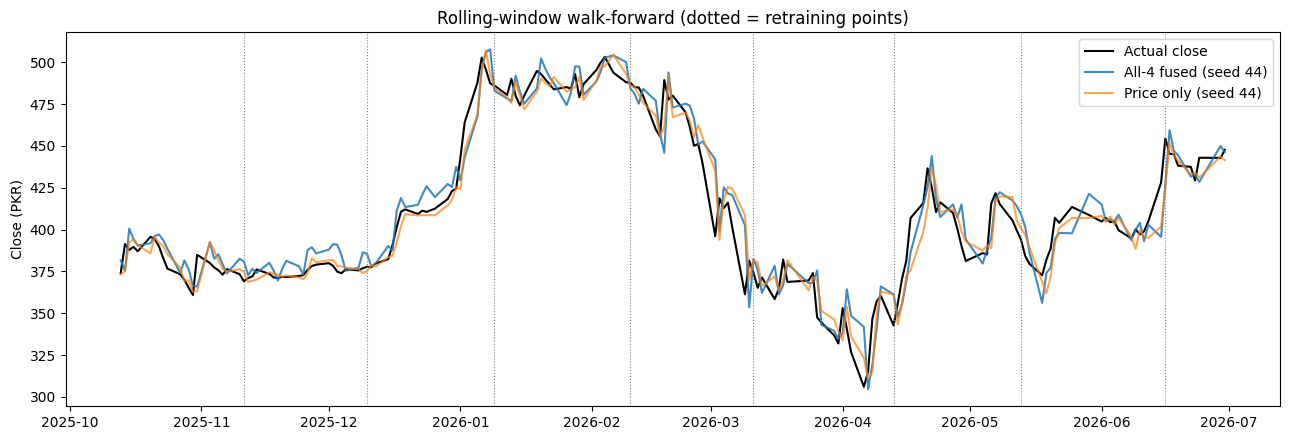

In [31]:
import matplotlib.pyplot as plt
FUSED = "All-4 fused" if "All-4 fused" in WF_MODELS else WF_MODELS[-1]
p = wf[wf.Model == FUSED].set_index("DATE").sort_index()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(p.index, p.actual, color="black", lw=1.5, label="Actual close")
ax.plot(p.index, p.pred, alpha=.85, label=f"{FUSED} (seed {SEED})")
q = wf[wf.Model == "Price"].set_index("DATE").sort_index()
ax.plot(q.index, q.pred, alpha=.7, label=f"Price only (seed {SEED})")
for d in p.reset_index().groupby("fold").DATE.first().iloc[1:]:
    ax.axvline(d, color="grey", ls=":", lw=.8)
ax.set_title("Rolling-window walk-forward (dotted = retraining points)")
ax.set_ylabel("Close (PKR)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/wf_rolling_predictions.png", dpi=200); plt.show()